<div style="background-color: #FFFF00; color: #000000; padding: 12px 18px; font-family: Arial, Helvetica, sans-serif;">
<strong style="color: #000000;">MINE-4101 Ciencia de Datos Aplicada · Universidad de los Andes · 2026-20</strong><br>
<span style="color: #000000;">Proyecto final · Entrega final · Actividad 10</span>
</div>

# Construcción y evaluación del modelo

Modelos que estiman la probabilidad de que cada predio pague el impuesto predial, y su evaluación frente a la línea base.

**Integrantes**

- Daniel Felipe Triviño Santana
- Nicolas Bedoya Figueroa
- Joubert Daniel Álvarez
- Gabriel Bejarano

**Qué pide el enunciado** (actividad 10, 20 % de la entrega final): entrenar modelos con al menos tres algoritmos y distintos conjuntos de hiperparámetros, evaluarlos cuantitativamente con las métricas del enfoque analítico y, en la medida de lo posible, cualitativamente, y establecer oportunidades de mejora.

**Punto de partida:** el enfoque analítico (sección 4 del [reporte](../reporte/reporte.pdf)) definió tres algoritmos (regresión logística, un árbol de decisión poco profundo y *gradient boosting*), la línea base (repetir el pago de 2025) y las métricas: ROC-AUC, log-loss y curva de calibración, reportadas por grupo (pagó en 2025, no pagó, predio nuevo). Usa los datos del [notebook 08](08-preparacion-de-datos.ipynb) y la partición del [notebook 09](09-estrategia-de-validacion.ipynb). El mejor modelo se guarda para el [producto de datos](../producto/README.md).

**Cómo hacerlo:** el [sitio de prácticas del curso](https://datascience-uniandes.github.io/PracticasMachineLearning/) es la referencia principal; para esta actividad, [práctica 2: Clasificación](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/), [práctica 5: Interpretabilidad](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-5/) y [práctica 7: Justicia](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-7/), y las guías [regresión logística](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/regresion-logistica/), [árbol de decisión](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/arbol-decision/), [gradient boosting](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/gradient-boosting/), [curva ROC](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/curva-roc/), [comparar métricas](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/comparar-metricas/), [impacto en el negocio](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/impacto-negocio/), [SHAP](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/shap/) y [guardar el modelo](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/guardar-modelo/). Si el notebook se aparta de ellas, lo dice y explica por qué.

**Estado:** la línea base, la regresión logística y el árbol de decisión (etapas 3, 4.1 y 4.2) tienen código e interpretación. Pendientes: el *gradient boosting* (4.3), la comparación y la elección del modelo (4.4) y las etapas 5 a 9.

## Tabla de contenido

| | Etapa | Qué se hace |
| --- | --- | --- |
| 1 | [Librerías y configuración](#librerias) | Librerías, rutas y estilo |
| 2 | [Carga de los datos y la partición](#carga) | Leer las salidas de los notebooks 08 y 09 |
| 3 | [Línea base](#base) | Repetir el pago de 2025 |
| 4 | [Algoritmos e hiperparámetros](#modelos) | Tres algoritmos, varios conjuntos de hiperparámetros, comparados en validación |
| 5 | [Evaluación cuantitativa](#cuantitativa) | El modelo elegido en prueba: ROC-AUC, log-loss y calibración, por grupo |
| 6 | [Evaluación cualitativa](#cualitativa) | Qué variables pesan y en qué casos se equivoca |
| 7 | [Del modelo al recaudo esperado](#recaudo) | La suma del impuesto por la probabilidad de pago, frente a lo recaudado |
| 8 | [Oportunidades de mejora](#mejora) | Qué haría mejor al modelo |
| 9 | [Guardar el mejor modelo](#guardar) | El archivo que usa el producto |

<a id="librerias"></a>

## 1. Librerías y configuración

Las librerías están en el entorno del proyecto (ver el [README](../../README.md#entorno-de-python)). Las rutas de los archivos que pasan de un notebook a otro, la semilla y las columnas reservadas están en [utilidades_modelado.py](utilidades_modelado.py), junto a este notebook.

In [1]:
import platform

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Rutas, semilla, columnas reservadas y estilo (utilidades_modelado.py, en esta carpeta)
import utilidades_modelado as um

um.configurar()

In [2]:
# Versiones con las que se ejecutó el notebook
print(f"Python {platform.python_version()}")
for libreria in (np, pd, mpl, sns, sklearn):
    print(f"{libreria.__name__} {libreria.__version__}")

Python 3.12.15
numpy 2.3.5
pandas 2.3.3
matplotlib 3.10.0
seaborn 0.13.2
sklearn 1.9.1


<a id="carga"></a>

## 2. Carga de los datos y la partición

**Salidas.** El repositorio es público: ninguna salida puede mostrar datos personales ni nada que identifique al municipio, y los valores de `um.COLUMNAS_RESERVADAS` no se muestran (ver la etapa 2 del [notebook 06](../../entrega-1/notebooks/06-entendimiento-de-los-datos.ipynb)). La variable objetivo y las que salen de la facturación se muestran solo agregadas.

In [3]:
um.exigir(um.ARCHIVO_PREPARADO, "ejecute antes el notebook 08-preparacion-de-datos.ipynb")
um.exigir(um.ARCHIVO_PARTICION, "ejecute antes el notebook 09-estrategia-de-validacion.ipynb")
datos = pd.read_parquet(um.ARCHIVO_PREPARADO).merge(pd.read_parquet(um.ARCHIVO_PARTICION), on="id_predio",
                                                    validate="one_to_one")

# Un DataFrame por subconjunto, con las características, la variable objetivo y el grupo del historial
entrenamiento, validacion, prueba = (datos[datos["subconjunto"] == s].reset_index(drop=True)
                                     for s in ["entrenamiento", "validación", "prueba"])
X_ent, y_ent = entrenamiento[um.CARACTERISTICAS], entrenamiento[um.OBJETIVO]
X_val, y_val = validacion[um.CARACTERISTICAS], validacion[um.OBJETIVO]
pd.DataFrame({"predios": [len(entrenamiento), len(validacion), len(prueba)],
              "% pagó 2026": [d[um.OBJETIVO].mean() * 100 for d in (entrenamiento, validacion, prueba)]},
             index=["entrenamiento", "validación", "prueba"]).round(1)

,predios,% pagó 2026
entrenamiento,13403,64.00
validación,2873,64.00
prueba,2873,64.00


<a id="base"></a>

## 3. Línea base

El enfoque analítico propuso como línea base repetir el pago de 2025. Para compararla con los modelos en log-loss y calibración hace falta una probabilidad, y "repetir 2025" no da ninguna para los predios sin registro de 2025. Se usa su versión probabilística: **la tasa de pago de 2026 de cada grupo del historial en entrenamiento**. Con el umbral de 0,5 clasifica igual que repetir 2025 (los que pagaron, pagan; los que no, no), y a los predios sin registro les asigna su tasa de pago (56 %), así que los clasifica como "paga".

Las métricas se reportan en total y por grupo (estrategia del notebook 09). En el grupo que no pagó 2025, validación y prueba tienen un solo pago, así que su ROC-AUC queda vacío y sus demás métricas se leen con cuidado.

In [4]:
tasa_por_grupo = entrenamiento.groupby(um.GRUPO)[um.OBJETIVO].mean()
display(tasa_por_grupo.mul(100).round(1).rename("% pagó 2026 en entrenamiento").to_frame())


def linea_base(d):
    return d[um.GRUPO].map(tasa_por_grupo).to_numpy()


p_base_val = linea_base(validacion)
base_val = um.metricas_por_grupo(validacion, p_base_val)
base_val.round(3)

,% pagó 2026 en entrenamiento
historial_2025,
No pagó 2025,0.40
Pagó 2025,80.30
Sin registro 2025,56.10


,predios,ROC-AUC,log-loss,precisión no paga,recall no paga,F1 no paga
Total,2873.00,0.77,0.47,1.00,0.39,0.56
No pagó 2025,405.00,NaN,0.02,1.00,1.00,1.00
Pagó 2025,1879.00,0.50,0.50,0.00,0.00,0.00
Sin registro 2025,589.00,0.50,0.69,0.00,0.00,0.00


**Interpretación.** La línea base le asigna a cada predio la tasa de pago de su grupo en entrenamiento: 80,3 % a los que pagaron 2025, 56,1 % a los que no tienen registro y 0,4 % a los que no pagaron. En validación tiene un ROC-AUC de 0,77 y un log-loss de 0,47.

Solo distingue entre grupos: dentro de cada uno, su ROC-AUC es 0,50. Con el umbral de 0,5 señala como "no paga" únicamente a quienes no pagaron 2025. Por eso su precisión es 1,00 y su recall solo 0,39: no detecta a ninguno de los que dejan de pagar entre los que pagaron 2025 ni entre los que no tienen registro. Los modelos tienen que mejorar dentro de esos dos grupos.

<a id="modelos"></a>

## 4. Algoritmos e hiperparámetros

Cada algoritmo va en un `Pipeline` con el preprocesador del notebook 08 (`um.crear_preprocesador`), que se ajusta solo con entrenamiento ([pipeline](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/pipeline/)). Cada conjunto de hiperparámetros se entrena con entrenamiento y se compara en validación ([selección de hiperparámetros](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/seleccion-hiperparametros/)). La tabla de cada algoritmo trae las métricas de validación, ordenadas por log-loss, y el log-loss de entrenamiento, para ver si hay sobreajuste. Prueba no se usa en esta etapa.

`evaluar_grilla` recorre una grilla de hiperparámetros y devuelve esa tabla y el pipeline del mejor conjunto. Sirve igual para los tres algoritmos.

In [5]:
from sklearn.model_selection import ParameterGrid


def evaluar_grilla(crear_pipeline, grilla):
    # Entrena un pipeline por conjunto de hiperparámetros y lo evalúa en validación
    filas, pipelines = [], []
    for parametros in ParameterGrid(grilla):
        pipeline = crear_pipeline().set_params(**parametros).fit(X_ent, y_ent)
        p_val = pipeline.predict_proba(X_val)[:, 1]
        p_ent = pipeline.predict_proba(X_ent)[:, 1]
        fila = {k.split("__")[-1]: v for k, v in parametros.items()}
        fila.update(um.metricas(y_val, p_val))
        fila["log-loss entrenamiento"] = um.metricas(y_ent, p_ent)["log-loss"]
        filas.append(fila)
        pipelines.append(pipeline)
    tabla = pd.DataFrame(filas).drop(columns="predios")
    mejor = int(tabla["log-loss"].idxmin())
    return tabla.sort_values("log-loss").round(3), pipelines[mejor]

### 4.1 Regresión logística

[Regresión logística](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/regresion-logistica/) con regularización L2, sobre las variables estandarizadas. Hiperparámetros:

- `C`: inverso de la fuerza de la regularización (0,01 a 10). Con valores bajos los coeficientes se encogen más.
- `class_weight`: sin pesos o `"balanced"`, que da más peso a la clase minoritaria ("no paga").
- `activar` (interacciones con el historial): sin o con el producto de cada variable numérica o binaria por el indicador de "pagó 2025" y de "sin registro de 2025". La logística suma los efectos de las variables y no encuentra sola que una variable pese distinto según el historial, como mostró el notebook 06 (`um.InteraccionesHistorial`).

Son 4 × 2 × 2 = 16 conjuntos.

In [6]:
from sklearn.linear_model import LogisticRegression


def crear_logistica():
    return Pipeline([
        ("preprocesamiento", um.crear_preprocesador().set_output(transform="pandas")),
        ("interacciones", um.InteraccionesHistorial()),
        ("modelo", LogisticRegression(max_iter=5000)),
    ])


grilla_logistica = {"modelo__C": [0.01, 0.1, 1, 10], "modelo__class_weight": [None, "balanced"],
                    "interacciones__activar": [False, True]}
tabla_logistica, mejor_logistica = evaluar_grilla(crear_logistica, grilla_logistica)
tabla_logistica

,activar,C,class_weight,ROC-AUC,log-loss,precisión no paga,recall no paga,F1 no paga,log-loss entrenamiento
12,True,1.00,None,0.82,0.43,0.88,0.58,0.70,0.42
10,True,0.10,None,0.82,0.43,0.89,0.58,0.70,0.43
14,True,10.00,None,0.82,0.43,0.88,0.58,0.70,0.42
4,False,1.00,None,0.82,0.44,0.86,0.55,0.67,0.43
6,False,10.00,None,0.82,0.44,0.86,0.55,0.67,0.43
2,False,0.10,None,0.82,0.44,0.85,0.56,0.67,0.43
8,True,0.01,None,0.82,0.44,0.88,0.57,0.69,0.44
13,True,1.00,balanced,0.82,0.45,0.77,0.64,0.70,0.45
11,True,0.10,balanced,0.82,0.46,0.77,0.64,0.70,0.45
15,True,10.00,balanced,0.82,0.46,0.77,0.64,0.69,0.45


**Interpretación.** Los 16 conjuntos quedan cerca: ROC-AUC entre 0,81 y 0,82 y log-loss entre 0,43 y 0,48. Lo que mueve el log-loss:

- **`class_weight="balanced"` lo empeora siempre** (0,45 a 0,48). Sube el recall de "no paga" a 0,64 o 0,65, pero desplaza las probabilidades, y el recaudo esperado necesita probabilidades bien calibradas.
- **Las interacciones con el historial lo mejoran** de 0,44 a 0,43.
- **`C` casi no importa entre 0,1 y 10.** Con 0,01 la regularización es demasiado fuerte (0,44 con interacciones y 0,46 sin ellas).

El mejor conjunto (C = 1, sin pesos, con interacciones) tiene un log-loss de 0,42 en entrenamiento y de 0,43 en validación: no hay sobreajuste.

### 4.2 Árbol de decisión

[Árbol de decisión](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/arbol-decision/) lo bastante poco profundo para que se pueda leer. Las variables no se estandarizan, porque al árbol no le cambia nada. Hiperparámetros:

- `max_depth`: de 2 a 6 niveles, y 8 y 10 para comprobar si un árbol más profundo mejora (con 6 quedaba en el borde de la grilla).
- `min_samples_leaf`: mínimo de predios por hoja (1, 20 o 100). Con hojas más grandes, las probabilidades son más estables y menos extremas, lo que importa para el log-loss.
- `class_weight`: sin pesos o `"balanced"`.

Son 7 × 3 × 2 = 42 conjuntos.

In [7]:
def crear_arbol():
    return Pipeline([
        ("preprocesamiento", um.crear_preprocesador(escalar=False)),
        ("modelo", DecisionTreeClassifier(random_state=um.SEMILLA)),
    ])


grilla_arbol = {"modelo__max_depth": [2, 3, 4, 5, 6, 8, 10], "modelo__min_samples_leaf": [1, 20, 100],
                "modelo__class_weight": [None, "balanced"]}
tabla_arbol, mejor_arbol = evaluar_grilla(crear_arbol, grilla_arbol)
tabla_arbol.head(12)

,class_weight,max_depth,min_samples_leaf,ROC-AUC,log-loss,precisión no paga,recall no paga,F1 no paga,log-loss entrenamiento
16,None,8,20,0.85,0.39,0.91,0.62,0.74,0.37
17,None,8,100,0.84,0.41,0.86,0.60,0.71,0.39
13,None,6,20,0.84,0.41,0.88,0.60,0.71,0.39
20,None,10,100,0.85,0.41,0.86,0.60,0.71,0.38
14,None,6,100,0.84,0.42,0.83,0.62,0.71,0.40
19,None,10,20,0.86,0.42,0.88,0.66,0.76,0.34
12,None,6,1,0.83,0.42,0.88,0.60,0.71,0.39
37,balanced,8,20,0.85,0.42,0.84,0.67,0.75,0.39
34,balanced,6,20,0.84,0.43,0.81,0.66,0.73,0.41
38,balanced,8,100,0.84,0.43,0.81,0.65,0.72,0.41


**Interpretación.** El árbol mejora con la profundidad hasta 8 niveles y no gana más con 10. El mejor conjunto (profundidad 8, al menos 20 predios por hoja, sin pesos) tiene un log-loss de 0,39 y un ROC-AUC de 0,85 en validación, con 0,37 de log-loss en entrenamiento: un sobreajuste leve.

Las hojas con un solo predio (`min_samples_leaf = 1`) dan probabilidades extremas y peor log-loss, y los pesos balanceados lo empeoran, como en la logística. Con 76 hojas, el árbol completo ya no es fácil de leer, pero sus primeros niveles sí (ver la lectura más abajo).

#### Los mejores conjuntos frente a la línea base

El mejor conjunto de cada algoritmo, en validación: en total y por grupo del historial, con el umbral de 0,5 y con el que maximiza el F1 de "no paga" en validación, y sus curvas ROC y de calibración ([curva ROC](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/curva-roc/)).

In [8]:
probabilidades_val = {"Línea base": p_base_val,
                      "Regresión logística": mejor_logistica.predict_proba(X_val)[:, 1],
                      "Árbol de decisión": mejor_arbol.predict_proba(X_val)[:, 1]}

comparacion = {}
for nombre, p in probabilidades_val.items():
    umbral = um.umbral_f1(y_val, p)
    por_grupo = um.metricas_por_grupo(validacion, p)
    por_grupo["umbral F1"] = umbral
    por_grupo["F1 no paga (umbral F1)"] = um.metricas_por_grupo(validacion, p, umbral)["F1 no paga"]
    comparacion[nombre] = por_grupo
comparacion = pd.concat(comparacion, names=["modelo", "grupo"])
comparacion.round(3)

predios  ROC-AUC  log-loss  \
modelo              grupo                                           
Línea base          Total              2873.00     0.77      0.47   
                    No pagó 2025        405.00      NaN      0.02   
                    Pagó 2025          1879.00     0.50      0.50   
                    Sin registro 2025   589.00     0.50      0.69   
Regresión logística Total              2873.00     0.82      0.43   
                    No pagó 2025        405.00      NaN      0.02   
                    Pagó 2025          1879.00     0.65      0.47   
                    Sin registro 2025   589.00     0.74      0.59   
Árbol de decisión   Total              2873.00     0.85      0.39   
                    No pagó 2025        405.00      NaN      0.04   
                    Pagó 2025          1879.00     0.68      0.45   
                    Sin registro 2025   589.00     0.86      0.43   

                                       precisión no paga  recall no paga  \
modelo              grupo                                                  
Línea base          Total                           1.00            0.39   
                    No pagó 2025                    1.00            1.00   
                    Pagó 2025                       0.00            0.00   
                    Sin registro 2025               0.00            0.00   
Regresión logística Total                           0.88            0.58   
                    No pagó 2025                    1.00            1.00   
                    Pagó 2025                       0.79            0.11   
                    Sin registro 2025               0.70            0.58   
Árbol de decisión   Total                           0.91            0.62   
                    No pagó 2025                    1.00            1.00   
                    Pagó 2025                       0.64            0.17   
                    Sin registro 2025               0.85            0.69   

                                       F1 no paga  umbral F1  \
modelo              grupo                                      
Línea base          Total                    0.56       0.57   
                    No pagó 2025             1.00       0.57   
                    Pagó 2025                0.00       0.57   
                    Sin registro 2025        0.00       0.57   
Regresión logística Total                    0.70       0.61   
                    No pagó 2025             1.00       0.61   
                    Pagó 2025                0.20       0.61   
                    Sin registro 2025        0.64       0.61   
Árbol de decisión   Total                    0.74       0.62   
                    No pagó 2025             1.00       0.62   
                    Pagó 2025                0.27       0.62   
                    Sin registro 2025        0.76       0.62   

                                       F1 no paga (umbral F1)  
modelo              grupo                                      
Línea base          Total                                0.65  
                    No pagó 2025                         1.00  
                    Pagó 2025                            0.00  
                    Sin registro 2025                    0.61  
Regresión logística Total                                0.70  
                    No pagó 2025                         1.00  
                    Pagó 2025                            0.21  
                    Sin registro 2025                    0.68  
Árbol de decisión   Total                                0.75  
                    No pagó 2025                         1.00  
                    Pagó 2025                            0.37  
                    Sin registro 2025                    0.77

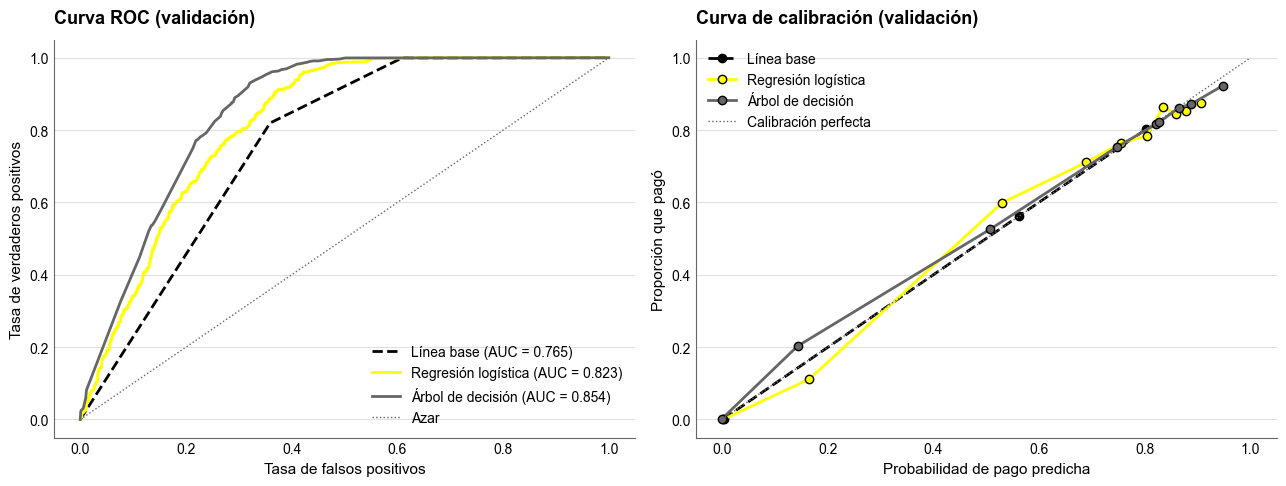

In [9]:
um.graficar_roc_calibracion(y_val, probabilidades_val, "(validación)")
plt.show()

**Interpretación.** Los dos modelos superan a la línea base en las métricas totales:

| | Línea base | Regresión logística | Árbol de decisión |
| --- | --- | --- | --- |
| Log-loss | 0,47 | 0,43 | 0,39 |
| ROC-AUC | 0,77 | 0,82 | 0,85 |
| F1 de "no paga" (umbral 0,5) | 0,56 | 0,70 | 0,74 |

La mejora está dentro de los grupos inciertos:

- **Sin registro de 2025:** ROC-AUC de 0,74 con la logística y 0,86 con el árbol. El árbol detecta el 69 % de los que no pagan, con 85 % de precisión.
- **Pagó 2025:** ROC-AUC de 0,65 y 0,68. Es el grupo más difícil: con el umbral de 0,5, los modelos solo señalan al 11 % y al 17 % de los que dejan de pagar. Con el umbral que maximiza el F1 en validación (0,61 y 0,62), el F1 del árbol en este grupo sube de 0,27 a 0,37.
- **No pagó 2025:** los tres aciertan con todos los que no pagan; el único pago de validación no permite medir más.

Las curvas de calibración de los tres siguen la diagonal, así que sus probabilidades sirven para el recaudo esperado. Solo se apartan en el tramo bajo: el árbol predice 0,14 donde pagó el 20 %, y la logística 0,17 donde pagó el 11 %.

#### Lectura de los modelos

- **Regresión logística:** los coeficientes de las variables estandarizadas, que se pueden comparar entre sí ([interpretar coeficientes](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/interpretar-coeficientes/)). Un coeficiente positivo sube la probabilidad de pagar.
- **Árbol:** sus primeros niveles, que son las reglas que más predios separan.
- **Los dos:** la importancia por permutación en validación, medida como cuánto empeora el log-loss al desordenar cada variable original. Permite comparar los dos modelos con la misma vara.

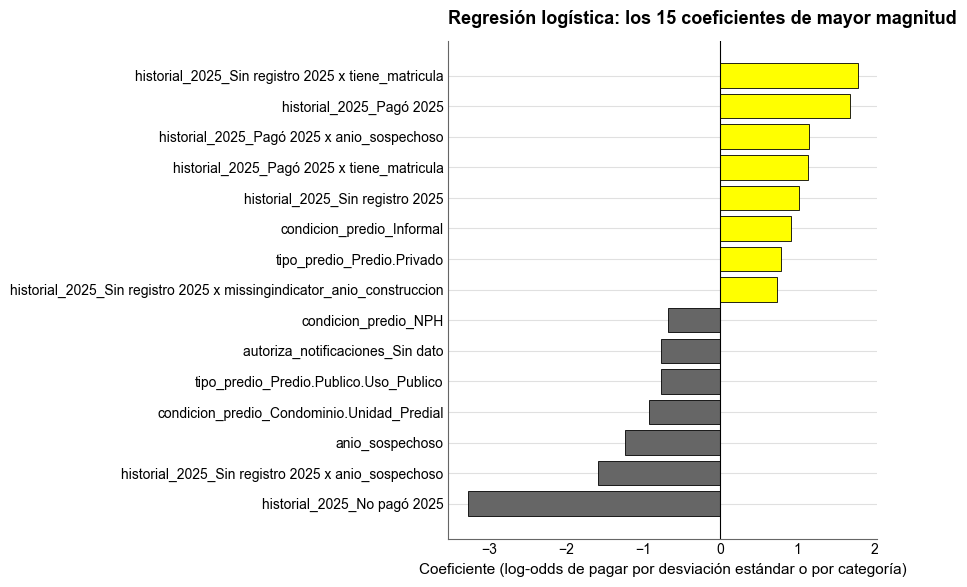

In [10]:
modelo_log = mejor_logistica.named_steps["modelo"]
nombres_log = mejor_logistica[:-1].get_feature_names_out()
coeficientes = pd.Series(modelo_log.coef_[0], index=nombres_log)
principales = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index[:15]).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([n.split("__", 1)[1] for n in principales.index],
        principales.values, color=[um.AMARILLO if v > 0 else um.GRIS for v in principales.values],
        edgecolor=um.NEGRO, linewidth=0.6)
ax.axvline(0, color=um.NEGRO, linewidth=0.8)
ax.set_xlabel("Coeficiente (log-odds de pagar por desviación estándar o por categoría)")
ax.set_title("Regresión logística: los 15 coeficientes de mayor magnitud")
plt.tight_layout(); plt.show()

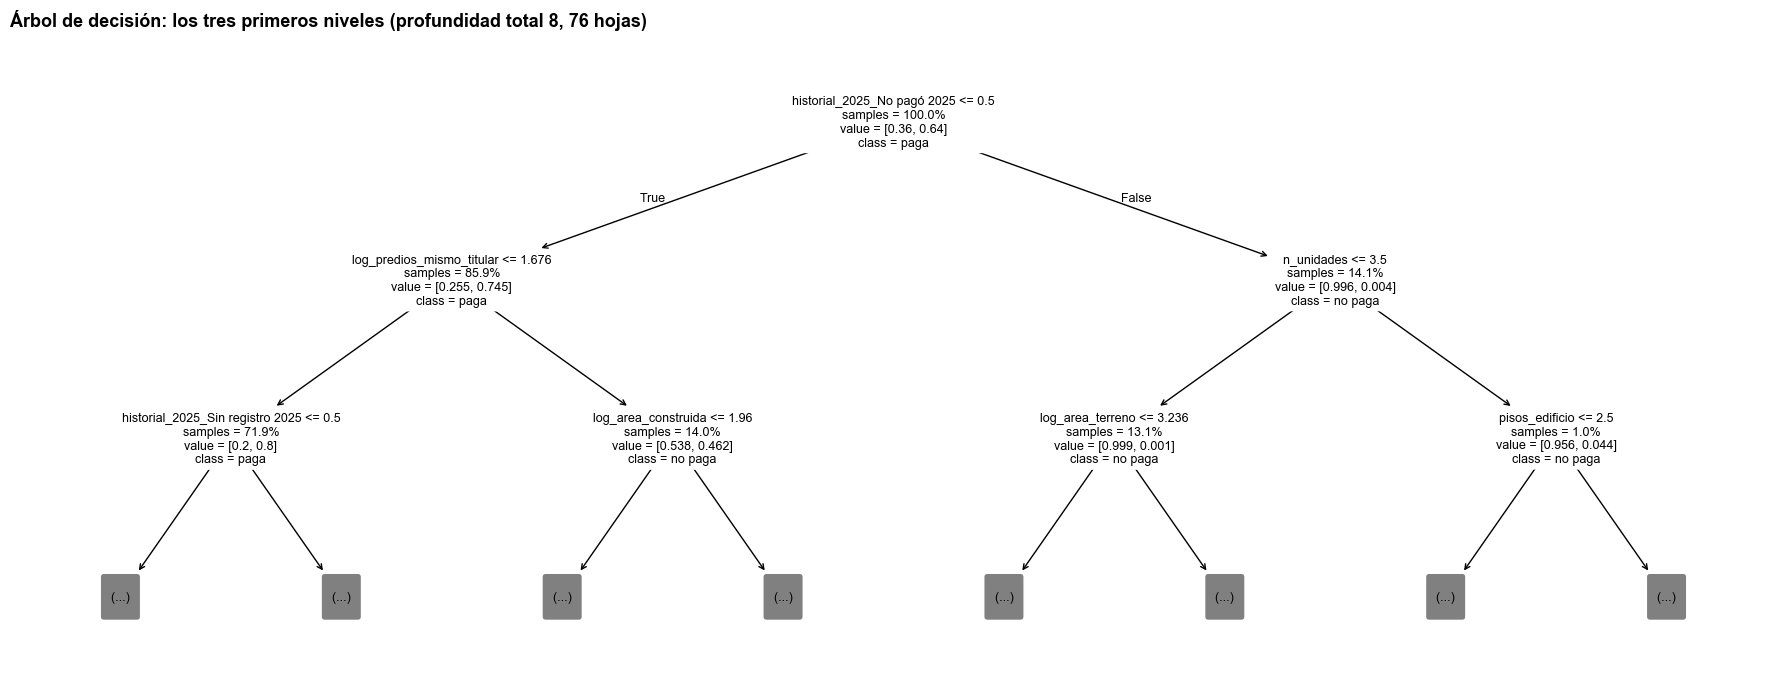

In [11]:
from sklearn.tree import plot_tree

arbol = mejor_arbol.named_steps["modelo"]
nombres_arbol = [n.split("__", 1)[1] for n in mejor_arbol[:-1].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arbol, max_depth=2, feature_names=nombres_arbol, class_names=["no paga", "paga"], filled=False,
          impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title(f"Árbol de decisión: los tres primeros niveles (profundidad total {arbol.get_depth()}, "
             f"{arbol.get_n_leaves()} hojas)")
plt.tight_layout(); plt.show()

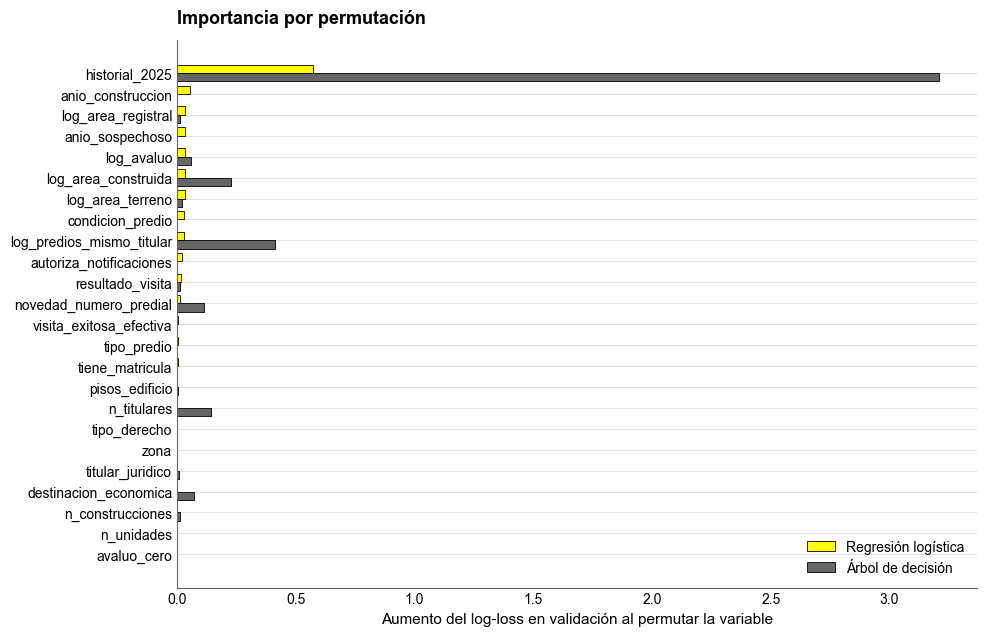

,Regresión logística,Árbol de decisión
historial_2025,0.57,3.21
anio_construccion,0.06,0.00
log_area_registral,0.04,0.01
anio_sospechoso,0.03,0.00
log_avaluo,0.03,0.06
log_area_construida,0.03,0.23
log_area_terreno,0.03,0.02
condicion_predio,0.03,0.00
log_predios_mismo_titular,0.03,0.41
autoriza_notificaciones,0.02,0.00


In [12]:
from sklearn.inspection import permutation_importance

importancias = {}
for nombre, modelo in {"Regresión logística": mejor_logistica, "Árbol de decisión": mejor_arbol}.items():
    r = permutation_importance(modelo, X_val, y_val, scoring="neg_log_loss", n_repeats=5,
                               random_state=um.SEMILLA, n_jobs=1)
    importancias[nombre] = pd.Series(r.importances_mean, index=um.CARACTERISTICAS)
importancias = pd.DataFrame(importancias).sort_values("Regresión logística", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6.5))
y_pos = np.arange(len(importancias))[::-1]
ax.barh(y_pos + 0.2, importancias["Regresión logística"], height=0.4, color=um.AMARILLO, edgecolor=um.NEGRO,
        linewidth=0.6, label="Regresión logística")
ax.barh(y_pos - 0.2, importancias["Árbol de decisión"], height=0.4, color=um.GRIS, edgecolor=um.NEGRO,
        linewidth=0.6, label="Árbol de decisión")
ax.set_yticks(y_pos, importancias.index)
ax.set_xlabel("Aumento del log-loss en validación al permutar la variable")
ax.set_title("Importancia por permutación"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
importancias.head(10).round(4)

**Interpretación.**

- **Regresión logística.** Los coeficientes más grandes son del historial: no haber pagado 2025 baja los log-odds de pagar en 3,3. Las interacciones aportan varios de los mayores. Tener matrícula inmobiliaria se asocia con pagar, sobre todo entre los que no tienen registro de 2025 (1,8) y los que pagaron (1,1). El año de construcción de relleno (2000) baja la probabilidad, más aún entre los que no tienen registro. Como el one-hot no elimina ninguna categoría, el coeficiente de cada categoría se lee frente al promedio de su variable: NPH y condominio tienen coeficientes negativos (pagan menos que el promedio de los regímenes), y también los predios públicos de uso público.
- **Árbol.** El primer corte es el historial. Entre los que pagaron 2025 o no tienen registro, el segundo corte es el número de predios del mismo titular: los predios de dueños con más de 47 predios (14 % del total) pagan el 46 %, frente al 80 % del resto de ese grupo, y dentro de ellos el área construida vuelve a separar. Entre los que no pagaron 2025 el árbol sigue partiendo, aunque casi ninguno paga (0,4 %): esas ramas no cambian la predicción.
- **Importancia por permutación.** En los dos modelos el historial es, con distancia, lo que más pesa. En la logística le siguen el año de construcción y las áreas, con pesos pequeños y parecidos. En el árbol le siguen el número de predios del mismo titular (0,41) y el área construida (0,23). La importancia del historial en el árbol (3,2) se ve inflada porque sus hojas tienen probabilidades extremas: al desordenar el historial, unos pocos predios quedan con probabilidades casi nulas de lo que realmente hicieron, y el log-loss se dispara.

Las dos lecturas coinciden con el notebook 06: el historial decide la mayor parte, y las características del predio pesan donde no decide. El árbol saca más provecho de ellas porque encuentra umbrales, como el de los dueños con muchos predios, que la logística no capta con un efecto lineal.

#### Oportunidades de mejora de la regresión logística y el árbol


1. **No linealidades en la logística.** El árbol encuentra un umbral en el número de predios del mismo titular (más de 47) que la logística, lineal en el logaritmo, no capta. Tramos o *splines* en esa variable y en las áreas (`KBinsDiscretizer` o `SplineTransformer`) podrían acercarla al árbol sin perder la lectura de los coeficientes.
2. **El grupo que pagó 2025 sigue siendo difícil** (ROC-AUC de 0,68 como máximo). Para anticipar quién deja de pagar harían falta datos del comportamiento de pago que quedaron fuera del alcance: la fecha de pago, los pagos parciales o la cartera de años anteriores.
3. **Dueños con muchos predios.** La partición es aleatoria entre predios, así que los predios de un mismo dueño quedan repartidos entre entrenamiento y validación. Es lo que pasará en el uso real (los mismos dueños la vigencia siguiente), pero conviene medir el desempeño con una partición por dueño para saber cuánto depende el modelo de ellos.
4. **El impuesto facturado quedó fuera** por la sospecha de fuga (etapa 5 del notebook 08). Si Hacienda confirma que el valor se fija antes del pago, podría volver como característica.
5. **Estabilidad del árbol.** Con profundidad 8 y 76 hojas, un árbol solo es sensible a los datos con los que se entrena. Un ensamble como el *gradient boosting* (4.3) debería dar probabilidades más estables y mejor calibradas en el tramo bajo.


### 4.3 Gradient boosting

Pendiente (issue #4): `HistGradientBoostingClassifier` en un pipeline con `um.crear_preprocesador(escalar=False)`, con la grilla evaluada con `evaluar_grilla` para que la tabla tenga las mismas columnas que las de 4.1 y 4.2.

In [13]:
# Pendiente: gradient boosting (por ejemplo, learning_rate, max_depth y max_iter)

### 4.4 Comparación y elección del modelo

Pendiente (issue #4): la tabla comparativa de los tres algoritmos y la línea base en validación (se puede extender `comparacion` y `probabilidades_val` con el *gradient boosting*), y la elección por log-loss.

In [14]:
# Pendiente: tabla comparativa en validación y elección del mejor modelo

<a id="cuantitativa"></a>

## 5. Evaluación cuantitativa

El modelo elegido, evaluado una sola vez en prueba, frente a la línea base y por grupo.

In [15]:
# Pendiente: ROC-AUC, log-loss y curva de calibración en prueba

<a id="cualitativa"></a>

## 6. Evaluación cualitativa

Importancia de las variables (por permutación o coeficientes), ejemplos agregados de aciertos y errores, y si el comportamiento tiene sentido para el negocio.

In [16]:
# Pendiente: interpretación del modelo

<a id="recaudo"></a>

## 7. Del modelo al recaudo esperado

$R_{\text{esperado}} = \sum_i \mathit{IPU}_i\,p_i$: con el impuesto facturado en 2026 y las probabilidades del modelo en prueba, comparado con lo efectivamente pagado. Solo cifras agregadas.

In [17]:
# Pendiente: recaudo esperado frente al observado, en prueba

<a id="mejora"></a>

## 8. Oportunidades de mejora

Pendiente: qué datos, variables o técnicas mejorarían el modelo.

<a id="guardar"></a>

## 9. Guardar el mejor modelo

El pipeline completo (transformaciones y modelo) en `entrega-2/producto/artefactos/modelo.joblib`, que no se sube al repositorio.

In [18]:
# Pendiente: um.CARPETA_ARTEFACTOS.mkdir(exist_ok=True); joblib.dump(mejor, um.ARCHIVO_MODELO)